# PathSnap · Member 2 · candidate scorer: training results and testing

**What this notebook does.** It loads the models and results saved by the real runs, re-scores the ten
`student_test` trips *live* with every saved model, and checks the new numbers against the saved results.
It also shows the cross-validation folds, the Bayesian-search history, the tuned-vs-untuned comparison and the
final model that Members 3 and 4 load.

**Provenance (please read).** The full cross-validation, fitting and Bayesian tuning were executed on a local
Windows laptop (CPU, Python 3.13, scikit-learn 1.7.2, LightGBM 4.7, CatBoost 1.2, Optuna) by the scripts
`pathsnap/models/run_member2.py` and `pathsnap/models/run_extra_models.py`. Those scripts call the same library
functions used in the optional training cells at the end of this notebook (`RUN_TRAINING`). The full run takes
hours on a CPU, so the cells that retrain are off by default and the notebook reads the saved outputs instead.
Every result file is listed, with its producer and timestamp, in
`reports/model-experiments/results_archive/MANIFEST.md`.

In [1]:
import sys, os, json, glob, pathlib, zipfile, subprocess, warnings
warnings.filterwarnings("ignore")
# --- Colab / Kaggle: upload the three zips from runs/colab to /content, then run this cell ---
if pathlib.Path("/content").exists() and not pathlib.Path("pathsnap").exists():
    for z in ("pathsnap_member2_code.zip", "pathsnap_dev_tables.zip", "pathsnap_saved_models_and_results.zip"):
        zipfile.ZipFile(f"/content/{z}").extractall("/content/PathSnap")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/PathSnap/requirements-models.txt"], check=True)
    os.chdir("/content/PathSnap")
ROOT = pathlib.Path.cwd()
if not (ROOT / "pathsnap").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

DATA = ROOT / "runs" / "dev_tables"                          # Member 1's tables, combined (pathsnap.models.devtables)
ART = ROOT / "artifacts" / "models"                          # final + tuned saved models
RES = ROOT / "reports" / "model-experiments"
ARCHIVE = RES / "results_archive"                            # the named copies of every run output
NB_OUT = RES / "notebook_outputs"                            # everything this notebook writes
NB_OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
RUN_TRAINING = False   # True retrains into runs/notebook_retrain_out (hours at full size); saved results are untouched
print("repo root:", ROOT)

repo root: C:\Users\ASUS\PathSnap_ML_App


## 1. Load the data tables
Three separate tables (per the team contract). **Candidates** and **observations** are inference inputs;
**references** are development answers, used only to build labels and to score predictions.

In [2]:
from pathsnap.models.training.experiments import load_data
train_full = load_data(DATA / "train")
test = load_data(DATA / "student_test")
rows = []
for name, d in (("train", train_full), ("student_test", test)):
    st = d.references.alignment_status.value_counts()
    rows.append({"split": name, "trips": len(d.trips()), "observations": len(d.observations),
                 "candidate_rows": len(d.candidates), "aligned": st.get("aligned", 0),
                 "ambiguous": st.get("ambiguous", 0), "unaligned": st.get("unaligned", 0)})
data_summary = pd.DataFrame(rows)
data_summary.to_csv(NB_OUT / "NB01_dataset_inventory__train_and_student_test_counts.csv", index=False)
data_summary

,split,trips,observations,candidate_rows,aligned,ambiguous,unaligned
0,train,80,208417,1978331,158564,27757,22096
1,student_test,10,19160,229773,15979,3160,21


## 2. Labels and features
Positive candidate = its arc ID equals the reference arc, on **aligned** observations only (ambiguous and unaligned
observations are excluded from training). Eight features in a fixed order; nullable features are imputed inside the
fitted pipeline.

In [3]:
from pathsnap.models.schema import FEATURE_ORDER
y = train_full.y
n_lab, n_pos = int((y >= 0).sum()), int((y == 1).sum())
print("feature order:", FEATURE_ORDER)
print(f"labelled candidate rows: {n_lab:,}   positives: {n_pos:,}   positive rate: {n_pos / n_lab:.3f}")
features_sample = pd.DataFrame(train_full.X[:8], columns=FEATURE_ORDER)
features_sample.insert(0, "arc_id", train_full.candidates["arc_id"].iloc[:8].to_numpy())
features_sample.insert(0, "obs_idx", train_full.candidates["obs_idx"].iloc[:8].to_numpy())
features_sample.insert(0, "trip_id", train_full.candidates["trip_id"].iloc[:8].to_numpy())
features_sample.to_csv(NB_OUT / "NB02_feature_matrix_sample__first_8_training_candidates.csv", index=False)
features_sample

feature order: ['along_arc_fraction', 'distance_m', 'heading_diff_deg', 'speed_mps', 'delta_t_s', 'distance_rank', 'distance_gap_to_min_m', 'n_candidates']
labelled candidate rows: 1,531,262   positives: 157,540   positive rate: 0.103


,trip_id,obs_idx,arc_id,along_arc_fraction,distance_m,heading_diff_deg,speed_mps,delta_t_s,distance_rank,distance_gap_to_min_m,n_candidates
0,00000001,0,2641,1.000000,32.210995,NaN,NaN,NaN,2.0,31.487947,3.0
1,00000001,0,64973,0.109775,0.723048,NaN,NaN,NaN,0.0,0.000000,3.0
2,00000001,0,117639,0.512692,15.138362,NaN,NaN,NaN,1.0,14.415314,3.0
3,00000001,1,64973,0.258531,0.277576,1.313575,43.649255,1.0,0.0,0.000000,2.0
4,00000001,1,117639,0.469944,16.086157,178.755789,43.649255,1.0,1.0,15.808581,2.0
5,00000001,2,64973,0.426565,1.840479,2.460404,49.338606,1.0,0.0,0.000000,2.0
6,00000001,2,117639,0.421659,13.908428,177.470232,49.338606,1.0,1.0,12.067949,2.0
7,00000001,3,64973,0.614283,6.149731,4.474509,55.235798,1.0,0.0,0.000000,2.0


## 3. Trip-grouped cross-validation folds
Every model used the same 5 folds over the 80 training trips; a trip never appears on both sides of a split.

In [4]:
from pathsnap.models.training.folds import trip_folds
fold_rows = []
for k, (tr, va) in enumerate(trip_folds(train_full.trips(), 5, SEED)):
    assert not set(tr) & set(va)
    fold_rows.append({"fold": k, "train_trips": len(tr), "validation_trips": len(va), "validation_trip_ids": " ".join(va)})
folds_table = pd.DataFrame(fold_rows)
folds_table.to_csv(NB_OUT / "NB03_cv_fold_assignment__5fold_trip_grouped_seed42.csv", index=False)
folds_table[["fold", "train_trips", "validation_trips"]]

,fold,train_trips,validation_trips
0,0,64,16
1,1,64,16
2,2,64,16
3,3,64,16
4,4,64,16


## 4. Saved cross-validation results (from the real runs)
Macro F1 per validation fold for each of the seven models, read from the per-model CV logs.

In [5]:
cv_files = sorted(glob.glob(str(ARCHIVE / "0*" / "02_cv_per_fold_results__*.json")))
cv_rows = []
for f in cv_files:
    j = json.load(open(f))
    for fr in j["folds"]:
        cv_rows.append({"model": j["model"], "fold": fr["fold"], "macro_f1": fr["macro_f1"], "top1": fr["top1_accuracy"],
                        "train_seconds": fr["train_seconds"]})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(NB_OUT / "NB04_cv_per_fold_macro_f1_and_top1__all_seven_models.csv", index=False)
cv_summary = cv_table.groupby("model").agg(cv_macro_f1_mean=("macro_f1", "mean"), cv_macro_f1_std=("macro_f1", "std"),
                                           cv_top1_mean=("top1", "mean")).sort_values("cv_macro_f1_mean", ascending=False)
cv_summary.round(4)

,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean
model,,,
lightgbm_ranker,0.7204,0.0415,0.8000
catboost,0.7149,0.0437,0.7971
random_forest,0.7118,0.0455,0.7974
hist_gradient_boosting,0.7100,0.0433,0.7967
decision_tree,0.7059,0.0453,0.7961
logistic_regression,0.6941,0.0505,0.7939
gaussian_nb,0.6805,0.0543,0.7897


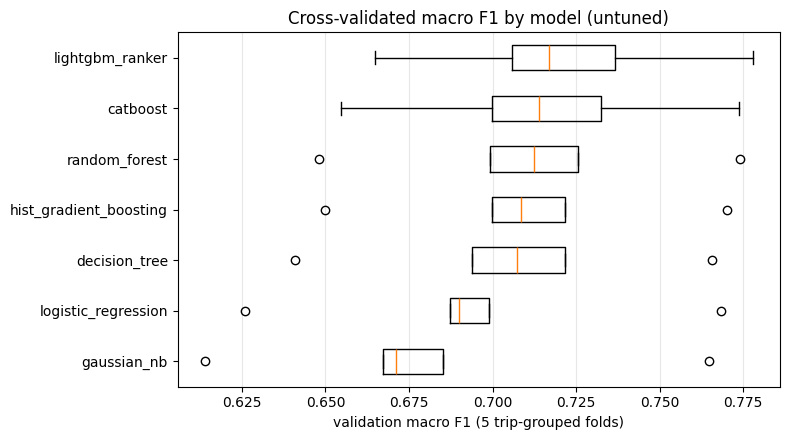

In [6]:
order = list(cv_summary.index[::-1])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([cv_table.loc[cv_table.model == m, "macro_f1"] for m in order], vert=False, labels=order)
ax.set_xlabel("validation macro F1 (5 trip-grouped folds)"); ax.set_title("Cross-validated macro F1 by model (untuned)")
ax.grid(axis="x", alpha=.3); fig.tight_layout()
fig.savefig(NB_OUT / "NB05_cv_macro_f1_by_fold__boxplot_all_seven_models.png", dpi=150); plt.show()

## 5. Re-score the student-test trips with every saved model
This is real inference: each saved model is loaded from disk and scores the candidate table of the ten
`student_test` trips (the references are read only afterwards, to score). The result is compared with the numbers
the original runs saved.

In [7]:
from pathsnap.models.training.scorer import CandidateScorer
from pathsnap.models.training.experiments import evaluate_scorer

SAVED = {
    "logistic_regression": RES / "comparison/models/logistic_regression.joblib",
    "gaussian_nb": RES / "comparison/models/gaussian_nb.joblib",
    "decision_tree": RES / "comparison/models/decision_tree.joblib",
    "random_forest": RES / "comparison/models/random_forest.joblib",
    "hist_gradient_boosting": RES / "comparison/models/hist_gradient_boosting.joblib",
    "lightgbm_ranker": RES / "extra/comparison/models/lightgbm_ranker.joblib",
    "catboost": RES / "extra/comparison/models/catboost.joblib",
    "lightgbm_ranker (tuned)": ART / "lightgbm_ranker_tuned.joblib",
    "catboost (tuned)": ART / "catboost_tuned.joblib",
    "FINAL pathsnap_scorer": ART / "pathsnap_scorer.joblib",
}
live = []
for label, path in SAVED.items():
    scorer = CandidateScorer.load(path)
    m = evaluate_scorer(scorer, test, repeats=1)["metrics"]
    live.append({"model": label, "top1": m["top1_accuracy"], "macro_f1": m["macro_f1"], "macro_precision": m["macro_precision"],
                 "macro_recall": m["macro_recall"], "log_loss": m["log_loss"], "log_loss_coverage": m["log_loss_coverage"],
                 "candidate_miss_rate": m["candidate_miss_rate"], "n_aligned": m["n_aligned"],
                 "inference_seconds": m["inference_seconds_median"]})
live = pd.DataFrame(live)
live.to_csv(NB_OUT / "NB06_student_test_live_rescoring__all_saved_models.csv", index=False)
live.round(4)

,model,top1,macro_f1,macro_precision,macro_recall,log_loss,log_loss_coverage,candidate_miss_rate,n_aligned,inference_seconds
0,logistic_regression,0.8269,0.6986,0.7326,0.6849,0.5745,0.9997,0.0003,15979,0.4121
1,gaussian_nb,0.8261,0.6903,0.7247,0.6764,0.9682,0.9997,0.0003,15979,0.4764
2,decision_tree,0.8258,0.6973,0.7300,0.6840,0.4550,0.9997,0.0003,15979,0.4084
3,random_forest,0.8282,0.7005,0.7339,0.6872,0.4479,0.9997,0.0003,15979,0.8027
4,hist_gradient_boosting,0.8270,0.6991,0.7321,0.6861,0.4429,0.9997,0.0003,15979,2.9077
5,lightgbm_ranker,0.8330,0.7180,0.7504,0.7043,0.4237,0.9997,0.0003,15979,0.6617
6,catboost,0.8301,0.7090,0.7415,0.6958,0.4353,0.9997,0.0003,15979,0.4087
7,lightgbm_ranker (tuned),0.8342,0.7155,0.7476,0.7018,0.4221,0.9997,0.0003,15979,0.7856
8,catboost (tuned),0.8297,0.7060,0.7386,0.6928,0.4340,0.9997,0.0003,15979,0.3992
9,FINAL pathsnap_scorer,0.8342,0.7155,0.7476,0.7018,0.4221,0.9997,0.0003,15979,0.7940


In [8]:
# Check the live re-scoring against the numbers saved by the original runs
saved = pd.concat([
    pd.read_csv(next(iter(glob.glob(str(ARCHIVE / "01_*" / "01_summary__*.csv"))))),
    pd.read_csv(next(iter(glob.glob(str(ARCHIVE / "02_*" / "01_summary__*.csv"))))),
]).set_index("model")[["test_top1", "test_macro_f1", "test_log_loss"]]
tv = pd.read_csv(next(iter(glob.glob(str(ARCHIVE / "03_*" / "03_tuned_vs_untuned__*.csv"))))).set_index("model")
tuned_saved = tv.loc[["lightgbm_ranker:tuned", "catboost:tuned"], ["test_top1", "test_macro_f1", "test_log_loss"]]
tuned_saved.index = ["lightgbm_ranker (tuned)", "catboost (tuned)"]
saved = pd.concat([saved, tuned_saved])
chk = live.set_index("model").join(saved, how="inner")
chk["top1_matches_saved"] = np.isclose(chk["top1"], chk["test_top1"], atol=1e-9)
chk["macro_f1_matches_saved"] = np.isclose(chk["macro_f1"], chk["test_macro_f1"], atol=1e-9)
chk["log_loss_matches_saved"] = np.isclose(chk["log_loss"], chk["test_log_loss"], atol=1e-6)
verify = chk[["top1", "test_top1", "top1_matches_saved", "macro_f1", "test_macro_f1", "macro_f1_matches_saved",
              "log_loss", "test_log_loss", "log_loss_matches_saved"]]
verify.to_csv(NB_OUT / "NB07_live_rescoring_vs_saved_run_numbers__consistency_check.csv")
print("all consistent with saved runs:", bool(chk.filter(like="matches_saved").all().all()))
verify.round(4)

all consistent with saved runs: True


,top1,test_top1,top1_matches_saved,macro_f1,test_macro_f1,macro_f1_matches_saved,log_loss,test_log_loss,log_loss_matches_saved
logistic_regression,0.8269,0.8269,True,0.6986,0.6986,True,0.5745,0.5745,True
gaussian_nb,0.8261,0.8261,True,0.6903,0.6903,True,0.9682,0.9682,True
decision_tree,0.8258,0.8258,True,0.6973,0.6973,True,0.4550,0.4550,True
random_forest,0.8282,0.8282,True,0.7005,0.7005,True,0.4479,0.4479,True
hist_gradient_boosting,0.8270,0.8270,True,0.6991,0.6991,True,0.4429,0.4429,True
lightgbm_ranker,0.8330,0.8330,True,0.7180,0.7180,True,0.4237,0.4237,True
catboost,0.8301,0.8301,True,0.7090,0.7090,True,0.4353,0.4353,True
lightgbm_ranker (tuned),0.8342,0.8342,True,0.7155,0.7155,True,0.4221,0.4221,True
catboost (tuned),0.8297,0.8297,True,0.7060,0.7060,True,0.4340,0.4340,True


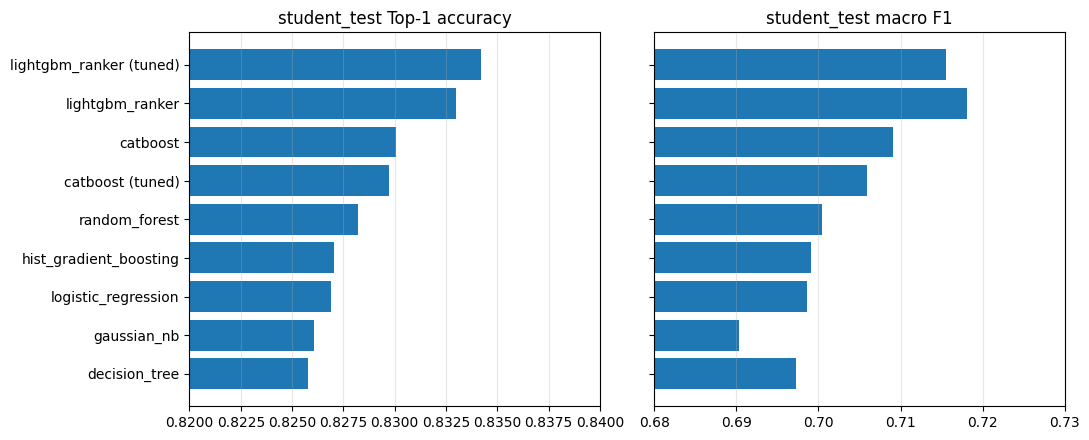

In [9]:
final_final = live.set_index("model").drop("FINAL pathsnap_scorer")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
final_final = final_final.sort_values("top1")
axes[0].barh(final_final.index, final_final["top1"]); axes[0].set_xlim(0.82, 0.84); axes[0].set_title("student_test Top-1 accuracy")
axes[1].barh(final_final.index, final_final["macro_f1"]); axes[1].set_xlim(0.68, 0.73); axes[1].set_title("student_test macro F1")
for a in axes: a.grid(axis="x", alpha=.3)
fig.tight_layout(); fig.savefig(NB_OUT / "NB08_student_test_top1_and_macro_f1__all_saved_models.png", dpi=150); plt.show()

## 6. Bayesian optimisation (Optuna TPE)
Objective: mean macro F1 over the 5 trip-grouped folds on the training trips only, 20 trials per model. The
`student_test` and reserved evaluator trips were never used by the search.

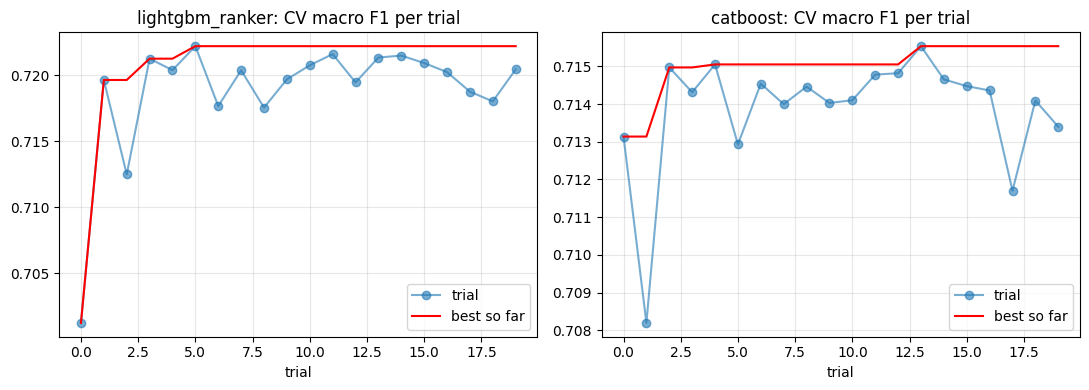

,model,n_trials,best_cv_macro_f1,best_params
0,lightgbm_ranker,20,0.722209,"{""n_estimators"": 410, ""learning_rate"": 0.03434..."
1,catboost,20,0.715535,"{""iterations"": 468, ""depth"": 8, ""learning_rate..."


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
best_rows = []
for ax, m in zip(axes, ["lightgbm_ranker", "catboost"]):
    t = pd.read_csv(glob.glob(str(ARCHIVE / "03_*" / f"01_optuna_tpe_trial_history__{m}__*.csv"))[0])
    s = json.load(open(glob.glob(str(ARCHIVE / "03_*" / f"02_optuna_search_space_and_best_params__{m}.json"))[0]))
    ax.plot(t["number"], t["value"], "o-", alpha=.6, label="trial"); ax.plot(t["number"], t["value"].cummax(), "r-", label="best so far")
    ax.set_title(f"{m}: CV macro F1 per trial"); ax.set_xlabel("trial"); ax.grid(alpha=.3); ax.legend()
    best_rows.append({"model": m, "n_trials": s["n_trials"], "best_cv_macro_f1": s["best_value"], "best_params": json.dumps(s["best_params"]),
                      "search_space": json.dumps(s["search_space"])})
fig.tight_layout(); fig.savefig(NB_OUT / "NB09_bayesian_trial_history__lightgbm_ranker_and_catboost.png", dpi=150); plt.show()
best_table = pd.DataFrame(best_rows)
best_table.to_csv(NB_OUT / "NB10_bayesian_best_parameters_and_search_space__lightgbm_ranker_and_catboost.csv", index=False)
best_table[["model", "n_trials", "best_cv_macro_f1", "best_params"]]

In [11]:
tuned_vs_untuned = pd.read_csv(next(iter(glob.glob(str(ARCHIVE / "03_*" / "03_tuned_vs_untuned__*.csv")))))
tvu = tuned_vs_untuned[["model", "cv_macro_f1_mean", "test_top1", "test_macro_f1", "test_macro_precision", "test_macro_recall",
                        "test_log_loss", "train_seconds"]]
tvu.to_csv(NB_OUT / "NB11_tuned_vs_untuned__student_test_same_10_trips.csv", index=False)
tvu.round(4)

,model,cv_macro_f1_mean,test_top1,test_macro_f1,test_macro_precision,test_macro_recall,test_log_loss,train_seconds
0,lightgbm_ranker:untuned,NaN,0.8330,0.7180,0.7504,0.7043,0.4237,5.8287
1,lightgbm_ranker:tuned,0.7222,0.8342,0.7155,0.7476,0.7018,0.4221,11.1562
2,catboost:untuned,NaN,0.8301,0.7090,0.7415,0.6958,0.4353,30.6911
3,catboost:tuned,0.7155,0.8297,0.7060,0.7386,0.6928,0.4340,58.1405


## 7. The final model
Chosen by the highest grouped-CV macro F1 on the training trips (the student-test trips were not used for selection),
and saved as `artifacts/models/pathsnap_scorer.joblib` for Members 3 and 4.

In [12]:
print(json.dumps(json.load(open(next(iter(glob.glob(str(ARCHIVE / "04_*" / "02_final_model_selection_record__*.json")))))), indent=2))
final = CandidateScorer.load(ART / "pathsnap_scorer.joblib")
print("model:", final.model_name, "| feature order:", final.feature_order)
print("library versions:", final.metadata()["versions"])

{
  "final_model": "lightgbm_ranker",
  "final_params": {
    "n_estimators": 410,
    "learning_rate": 0.034345084207755734,
    "num_leaves": 53,
    "min_child_samples": 123,
    "reg_lambda": 2.1142332035497158e-06
  },
  "selection_cv_macro_f1": 0.7222088331878992,
  "selection_rule": "highest grouped-CV macro F1 on train (student_test not used)",
  "artifact": "artifacts\\models\\pathsnap_scorer.joblib",
  "rf_tuning": "skipped by decision (time cost; untuned baseline kept)"
}
model: lightgbm_ranker | feature order: ['along_arc_fraction', 'distance_m', 'heading_diff_deg', 'speed_mps', 'delta_t_s', 'distance_rank', 'distance_gap_to_min_m', 'n_candidates']
library versions: {'python': '3.13.14', 'scikit-learn': '1.7.2', 'numpy': '2.2.6', 'pandas': '2.3.2', 'joblib': '1.5.2'}


In [13]:
# Inference with candidates + observations only (no reference columns reach the scorer)
one_trip = test.trips()[0]
cand = test.candidates[test.candidates.trip_id == one_trip].head(3000)
obs = test.observations[test.observations.trip_id == one_trip]
scored, matches = final.score(cand, obs)
scored.head(10).to_csv(NB_OUT / "NB12_final_model_sample_scored_candidates__emission_prob.csv", index=False)
matches.head(10).to_csv(NB_OUT / "NB13_final_model_sample_top1_matches.csv", index=False)
print("emissions sum to 1 per observation:", bool(np.allclose(scored.groupby(["trip_id", "obs_idx"]).emission_prob.sum(), 1.0)))
scored.head(10)

emissions sum to 1 per observation: True


,trip_id,obs_idx,arc_id,along_arc_fraction,distance_m,heading_diff_deg,speed_mps,delta_t_s,emission_prob
0,00000000,0,212,1.000000,46.009983,NaN,NaN,NaN,0.000445
1,00000000,0,17630,0.872796,6.115563,NaN,NaN,NaN,0.457596
2,00000000,0,17633,0.000000,46.009983,NaN,NaN,NaN,0.002286
3,00000000,0,17634,0.127204,6.115563,NaN,NaN,NaN,0.512560
4,00000000,0,17635,0.139846,27.679154,NaN,NaN,NaN,0.016663
5,00000000,0,17668,0.860154,27.679154,NaN,NaN,NaN,0.010450
6,00000000,1,211,0.000000,55.862373,25.215024,23.64927,1.0,0.000134
7,00000000,1,212,1.000000,22.664663,165.816671,23.64927,1.0,0.000182
8,00000000,1,17630,0.936786,0.367339,14.067295,23.64927,1.0,0.896689
9,00000000,1,17633,0.000000,22.664663,14.183329,23.64927,1.0,0.001379


## 8. Optional: retrain from this notebook (off by default)
Set `RUN_TRAINING = True` in the first cell to run the same training and tuning functions on a small subset of the
training trips (3 folds, 3 trials). Results go to `runs/notebook_retrain_out` and never overwrite the saved results.
The reported full-size numbers above come from the script runs described at the top.

In [14]:
if RUN_TRAINING:
    from pathsnap.models.training.experiments import run_comparison
    from pathsnap.models.training.models import ALL_MODEL_NAMES
    from pathsnap.models.tuning.bayes import bayes_search
    sub = train_full.subset(train_full.trips()[::4])
    out = ROOT / "runs" / "notebook_retrain_out"
    table = run_comparison(sub, test, out / "comparison", models=ALL_MODEL_NAMES, n_splits=3, seed=SEED)
    display(table[["model", "cv_macro_f1_mean", "test_top1", "test_macro_f1", "train_seconds"]].round(4))
    search = bayes_search("lightgbm_ranker", sub, 3, out / "tuning", 3, SEED)
    print(search["best_value"], search["best_params"])
else:
    print("RUN_TRAINING is False: showing saved results only.")

RUN_TRAINING is False: showing saved results only.


## Files written by this notebook
All outputs go to `reports/model-experiments/notebook_outputs/` with an `NBnn_` prefix, in the order they are produced.

In [15]:
pd.DataFrame({"file": sorted(p.name for p in NB_OUT.iterdir())})

,file
0,NB01_dataset_inventory__train_and_student_test...
1,NB02_feature_matrix_sample__first_8_training_c...
2,NB03_cv_fold_assignment__5fold_trip_grouped_se...
3,NB04_cv_per_fold_macro_f1_and_top1__all_seven_...
4,NB05_cv_macro_f1_by_fold__boxplot_all_seven_mo...
5,NB06_student_test_live_rescoring__all_saved_mo...
6,NB07_live_rescoring_vs_saved_run_numbers__cons...
7,NB08_student_test_top1_and_macro_f1__all_saved...
8,NB09_bayesian_trial_history__lightgbm_ranker_a...
9,NB10_bayesian_best_parameters_and_search_space...
